# Modelo — detecção de intenção de movimento no BCI Competition IV 2a

Pergunta: o EEG permite detectar **se** a pessoa está imaginando um movimento, em alguém que o
modelo nunca viu? Cada trial gera duas amostras do mesmo sujeito:

- **repouso:** 1,5 s antes do cue, com a cruz de fixação e antes de qualquer instrução;
- **intenção:** de 1,5 s a 3,0 s após o cue, depois que a seta some (1,25 s), para não detectar a
  resposta visual à seta.

Dois modelos, treinados em [`../src/train.py`](../src/train.py):

- **EEGConformer** (Song et al., *EEG Conformer*, IEEE TNSRE 31, 2023): convolução + Transformer
  sobre o sinal (22 canais × 192 amostras);
- **MLP:** recebe 44 características, o log da potência nas bandas mu (8–12 Hz) e beta (13–30 Hz) de
  cada canal. O MLP não enxerga a vizinhança no tempo, por isso não recebe o sinal cru.

As predições (`fact_prediction`) entram no esquema estrela de [`01_dados_2a.ipynb`](01_dados_2a.ipynb)
e são consultadas aqui com DuckDB.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_auc_score, roc_curve

sys.path.insert(0, "..")
from src.train import TEST_SUBJECTS, TRAIN_SUBJECTS, VAL_SUBJECTS

data_dir = Path("..") / "data"
con = duckdb.connect()
for table in ["fact_trial", "dim_class", "dim_subject"]:
    con.sql(f"CREATE VIEW {table} AS SELECT * FROM '{(data_dir / 'processed').as_posix()}/{table}.parquet'")
for table in ["fact_prediction", "training_history"]:
    con.sql(f"CREATE VIEW {table} AS SELECT * FROM '{(data_dir / 'predictions').as_posix()}/{table}.parquet'")

# uma linha por predição, com o membro imaginado, o artefato e a demografia vindos das dimensões
pred = con.sql("""
    SELECT p.*, c.class_name, t.has_artifact, s.age, s.sex
    FROM fact_prediction p
    JOIN fact_trial t USING (trial_id)
    JOIN dim_class c USING (class_id)
    JOIN dim_subject s ON s.subject_id = p.subject_id
""").df()
pred["correct"] = pred["y_true"] == pred["y_pred"]
test = pred[pred["split"] == "teste"]
MODELS = ["eegconformer", "mlp"]
print(pred["model_version"].unique())

C:\Documentos\GitHub\data-engineering-multimodal-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<ArrowStringArray>
['eegconformer_braindecode-1.8.1_intencao-repouso_split-fixo_seed42_v3', 'mlp_braindecode-1.8.1_intencao-repouso_split-fixo_seed42_v3']
Length: 2, dtype: str


## Pipeline de dados e treino

A divisão é **por paciente**, fixada antes de qualquer ajuste:

- **treino** (A01–A05): ajusta os pesos e o z-score;
- **validação** (A06–A07): escolhe a época, o limiar e o modelo;
- **teste** (A08–A09): avalia a escolha final, uma única vez.

Cada etapa filtra os dados. Os trials marcados como artefato pela fonte ficam em quarentena no treino
e na validação; o teste usa todos, como num uso real. Cada trial usado gera 2 amostras.

In [2]:
con.sql(f"""
    WITH t AS (
        SELECT CASE WHEN subject_id IN {tuple(TRAIN_SUBJECTS)} THEN '1. treino'
                    WHEN subject_id IN {tuple(VAL_SUBJECTS)} THEN '2. validação'
                    ELSE '3. teste' END AS conjunto, has_artifact
        FROM fact_trial
    )
    SELECT conjunto, COUNT(*) AS trials, SUM(has_artifact::INT)::INT AS com_artefato,
           CASE WHEN conjunto = '3. teste' THEN COUNT(*)
                ELSE COUNT(*) - SUM(has_artifact::INT)::INT END AS trials_usados,
           2 * trials_usados AS amostras
    FROM t GROUP BY conjunto ORDER BY conjunto
""").df()

,conjunto,trials,com_artefato,trials_usados,amostras
0,1. treino,2880,202,2678,5356
1,2. validação,1152,170,982,1964
2,3. teste,1152,116,1152,2304


## Etapas de treino

1. **Pré-treino:** não usado nos dois modelos, que são treinados do zero. Um modelo de fundação de
   EEG pré-treinado em outro corpus (CBraMod) é testado como extrator fixo no fim do notebook.
2. **Treino supervisionado:** do zero, ajustando todos os pesos, nos pares amostra → repouso ou
   intenção, com os dados já separados por paciente.
3. **Ajuste por preferência:** não se aplica; é uma etapa de modelos de linguagem.
4. **Inferência:** pesos fixos, aplicados à validação e ao teste; o resultado é `fact_prediction`.

Pré-processamento e regularização:

- **z-score** ajustado só no treino e aplicado igual na validação e no teste. Normalizar com o dataset
  inteiro vazaria informação. Por canal no sinal; por característica no MLP.
- Não há variável categórica de entrada, então **one-hot** não se aplica; o z-score já põe as entradas
  na mesma escala, sem precisar de **min–max**.
- **Regularização:** L2 (`weight_decay`) e dropout de 0,5 nos dois modelos.

## Overfitting

Perda no treino, perda na validação e área sob a curva ROC na validação, por época. O modelo
guardado é o da época com maior área sob a curva ROC na validação (parada antecipada), marcada
com a linha tracejada.

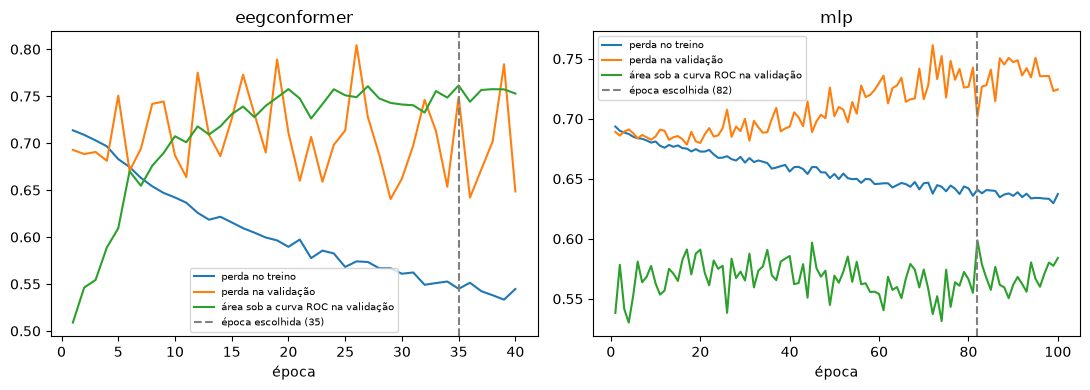

In [3]:
history = con.sql("SELECT * FROM training_history ORDER BY model, epoch").df()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (model, h) in zip(axes, history.groupby("model")):
    best = h.loc[h["val_auc"].idxmax(), "epoch"]
    ax.plot(h["epoch"], h["train_loss"], label="perda no treino")
    ax.plot(h["epoch"], h["val_loss"], label="perda na validação")
    ax.plot(h["epoch"], h["val_auc"], label="área sob a curva ROC na validação")
    ax.axvline(best, ls="--", c="gray", label=f"época escolhida ({best})")
    ax.set(title=model, xlabel="época")
    ax.legend(fontsize=7)
plt.tight_layout()

## Limiar e escolha do modelo na validação

O limiar de cada modelo maximiza a acurácia balanceada na validação e é fixado antes do teste. O
modelo usado na análise de erros é o de maior área sob a curva ROC na validação.

In [4]:
validation = con.sql("""
    SELECT model, ROUND(ANY_VALUE(threshold), 3) AS limiar, COUNT(*) AS amostras
    FROM fact_prediction WHERE split = 'validacao' GROUP BY model ORDER BY model
""").df().set_index("model")
val = pred[pred["split"] == "validacao"]
validation["área sob a curva ROC"] = [
    round(roc_auc_score(g["y_true"], g["p_intencao"]), 3) for _, g in val.groupby("model")]
chosen = validation["área sob a curva ROC"].idxmax()
print("modelo escolhido:", chosen)
validation

modelo escolhido: eegconformer


,limiar,amostras,área sob a curva ROC
model,,,
eegconformer,0.140,1964,0.761
mlp,0.461,1964,0.599


## Matriz de confusão no teste

Positivo = intenção. Linhas são a janela verdadeira e colunas, a predita, em dois limiares: 0,5 e o
limiar escolhido na validação.

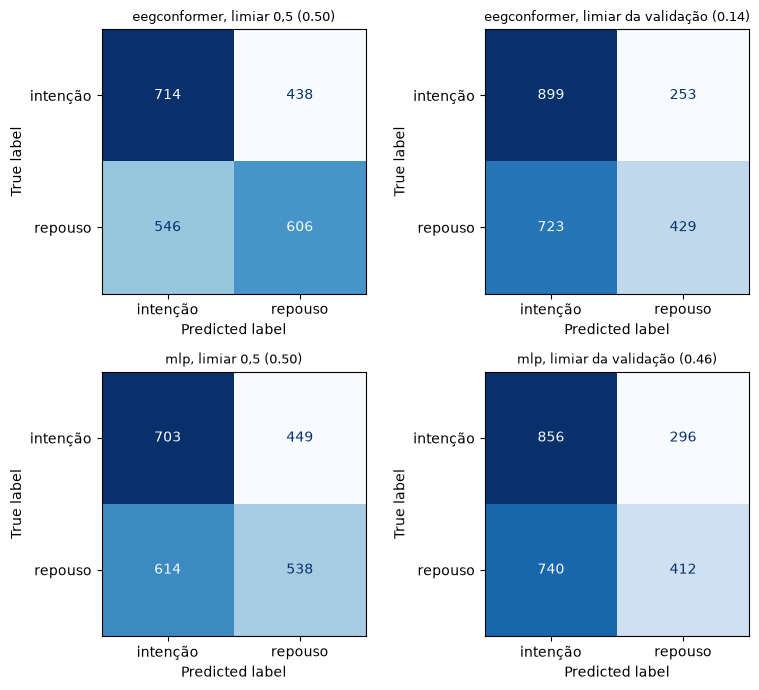

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, model in zip(axes, MODELS):
    g = test[test["model"] == model]
    for ax, (label, threshold) in zip(row, [("0,5", 0.5), ("da validação", g["threshold"].iat[0])]):
        cm = confusion_matrix(g["y_true"], (g["p_intencao"] >= threshold).astype(int), labels=[1, 0])
        ConfusionMatrixDisplay(cm, display_labels=["intenção", "repouso"]).plot(
            ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{model}, limiar {label} ({threshold:.2f})", fontsize=9)
plt.tight_layout()

## Métricas no teste

Com VP = verdadeiro positivo, FN = falso negativo, FP = falso positivo e VN = verdadeiro negativo:

- **sensibilidade** = VP / (VP + FN): das intenções reais, quantas detectamos;
- **especificidade** = VN / (VN + FP): dos repousos reais, quantos descartamos;
- **precisão** = VP / (VP + FP): das amostras sinalizadas, quantas eram intenção;
- **acurácia** = (VP + VN) / total.

Todas são proporções, com intervalo de confiança de 95% de Wilson. Denominador zero torna a métrica
indefinida. A precisão depende da prevalência, que aqui é 50% por construção.

In [6]:
def wilson(k, n):
    if n == 0:
        return np.nan, np.nan, np.nan
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return k / n, ci.low, ci.high


def confusion_metrics(y_true, y_pred):
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    return {"sensibilidade": (tp, tp + fn), "especificidade": (tn, tn + fp),
            "precisão": (tp, tp + fp), "acurácia": (tp + tn, tp + fn + fp + tn)}


rows = []
for model in MODELS:
    g = test[test["model"] == model]
    for label, threshold in [("0,5", 0.5), ("validação", g["threshold"].iat[0])]:
        y_pred = (g["p_intencao"] >= threshold).astype(int)
        for metric, (k, n) in confusion_metrics(g["y_true"], y_pred).items():
            value, low, high = wilson(k, n)
            rows.append({"modelo": model, "limiar": f"{label} ({threshold:.2f})", "métrica": metric,
                         "valor": value, "limite inferior": low, "limite superior": high})
results = pd.DataFrame(rows).set_index(["modelo", "limiar", "métrica"])
(100 * results).round(1).add_suffix(" (%)")

valor (%)  limite inferior (%)  \
modelo       limiar           métrica                                          
eegconformer 0,5 (0.50)       sensibilidade        62.0                 59.1   
                              especificidade       52.6                 49.7   
                              precisão             56.7                 53.9   
                              acurácia             57.3                 55.3   
             validação (0.14) sensibilidade        78.0                 75.6   
                              especificidade       37.2                 34.5   
                              precisão             55.4                 53.0   
                              acurácia             57.6                 55.6   
mlp          0,5 (0.50)       sensibilidade        61.0                 58.2   
                              especificidade       46.7                 43.8   
                              precisão             53.4                 50.7   
                              acurácia             53.9                 51.8   
             validação (0.46) sensibilidade        74.3                 71.7   
                              especificidade       35.8                 33.0   
                              precisão             53.6                 51.2   
                              acurácia             55.0                 53.0   

                                              limite superior (%)  
modelo       limiar           métrica                              
eegconformer 0,5 (0.50)       sensibilidade                  64.7  
                              especificidade                 55.5  
                              precisão                       59.4  
                              acurácia                       59.3  
             validação (0.14) sensibilidade                  80.3  
                              especificidade                 40.1  
                              precisão                       57.8  
                              acurácia                       59.6  
mlp          0,5 (0.50)       sensibilidade                  63.8  
                              especificidade                 49.6  
                              precisão                       56.1  
                              acurácia                       55.9  
             validação (0.46) sensibilidade                  76.7  
                              especificidade                 38.6  
                              precisão                       56.1  
                              acurácia                       57.1

## Curva ROC no teste

A curva mostra todos os limiares de uma vez; a área sob ela não depende do limiar escolhido. O ponto
marca o limiar da validação.

In [ ]:
NAMES = {"eegconformer": "EEGConformer", "mlp": "perceptron multicamadas (MLP)"}
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for model in MODELS:
    g = test[test["model"] == model]
    fpr, tpr, _ = roc_curve(g["y_true"], g["p_intencao"])
    auc = roc_auc_score(g["y_true"], g["p_intencao"])
    line, = ax.plot(100 * fpr, 100 * tpr, label=f"{NAMES[model]}, área = {auc:.2f}".replace(".", ","))
    sens = g.loc[g["y_true"] == 1, "y_pred"].mean()
    spec = 1 - g.loc[g["y_true"] == 0, "y_pred"].mean()
    ax.plot(100 * (1 - spec), 100 * sens, "o", ms=8, color=line.get_color())
ax.plot([0, 100], [0, 100], ls="--", c="gray", label="chute, área = 0,50")
ax.plot([], [], "o", c="black", label="limiar escolhido na validação")
ax.set(xlabel="repousos confundidos com intenção (%)\n(1 − especificidade)",
       ylabel="intenções detectadas (%)\n(sensibilidade)",
       title="Curva ROC no teste (A08 e A09)", xlim=(0, 100), ylim=(0, 100), aspect="equal")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

## Comparação dos modelos: McNemar e DeLong

Os dois modelos classificam as mesmas amostras de teste, então os testes são pareados:

- **McNemar** (acertos e erros, no limiar da validação): usa só as amostras em que os modelos
  discordam, com o teste binomial exato (Dietterich, *Neural Computation*, 1998);
- **DeLong** (área sob a curva ROC, sem limiar): compara as duas áreas levando em conta que vêm das
  mesmas amostras (DeLong et al., *Biometrics*, 1988).

In [8]:
paired = test.pivot(index="sample_id", columns="model", values="correct")
only_conformer = int((paired["eegconformer"] & ~paired["mlp"]).sum())
only_mlp = int((~paired["eegconformer"] & paired["mlp"]).sum())
p_mcnemar = stats.binomtest(only_conformer, only_conformer + only_mlp).pvalue
print(f"McNemar: só o EEGConformer acerta {only_conformer}, só o MLP acerta {only_mlp}, p = {p_mcnemar:.3g}")


def delong(y_true, score_a, score_b):
    """Teste de DeLong para duas áreas sob a curva ROC nas mesmas amostras."""
    pos, neg = y_true == 1, y_true == 0
    aucs, v10, v01 = [], [], []
    for score in (score_a, score_b):
        # comparação de cada positivo com cada negativo: 1 se o positivo tem saída maior, 0,5 se empata
        psi = (score[pos][:, None] > score[neg][None, :]) + 0.5 * (score[pos][:, None] == score[neg][None, :])
        aucs.append(psi.mean())
        v10.append(psi.mean(axis=1))
        v01.append(psi.mean(axis=0))
    s10, s01 = np.cov(v10), np.cov(v01)
    var = (s10[0, 0] + s10[1, 1] - 2 * s10[0, 1]) / pos.sum() + (s01[0, 0] + s01[1, 1] - 2 * s01[0, 1]) / neg.sum()
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return aucs, 2 * stats.norm.sf(abs(z))


scores = test.pivot(index="sample_id", columns="model", values="p_intencao")
labels = test.drop_duplicates("sample_id").set_index("sample_id").loc[scores.index, "y_true"].to_numpy()
(auc_conformer, auc_mlp), p_delong = delong(labels, scores["eegconformer"].to_numpy(), scores["mlp"].to_numpy())
print(f"DeLong: área do EEGConformer {auc_conformer:.3f}, do MLP {auc_mlp:.3f}, p = {p_delong:.3g}")

McNemar: só o EEGConformer acerta 417, só o MLP acerta 357, p = 0.0339
DeLong: área do EEGConformer 0.600, do MLP 0.561, p = 0.00441


## Erros por sujeito

Sensibilidade e especificidade de cada sujeito de teste, no limiar da validação, com intervalo de
confiança de 95% de Wilson.

In [9]:
def fmt(k, n):
    value, low, high = wilson(k, n)
    return f"{100 * value:.1f}% ({100 * low:.1f}–{100 * high:.1f}%)"


rows = []
for (model, subject), g in test.groupby(["model", "subject_id"]):
    mi, rest = g[g["y_true"] == 1], g[g["y_true"] == 0]
    rows.append({"modelo": model, "sujeito": subject,
                 "área sob a curva ROC": round(roc_auc_score(g["y_true"], g["p_intencao"]), 3),
                 "sensibilidade (intervalo)": fmt(mi["correct"].sum(), len(mi)),
                 "especificidade (intervalo)": fmt(rest["correct"].sum(), len(rest)),
                 "idade": g["age"].iat[0], "sexo": g["sex"].iat[0]})
pd.DataFrame(rows).set_index(["modelo", "sujeito"])

área sob a curva ROC sensibilidade (intervalo)  \
modelo       sujeito                                                   
eegconformer A08                     0.656        74.8% (71.1–78.2%)   
             A09                     0.562        81.2% (77.9–84.2%)   
mlp          A08                     0.548        68.8% (64.9–72.4%)   
             A09                     0.572        79.9% (76.4–82.9%)   

                     especificidade (intervalo)  idade sexo  
modelo       sujeito                                         
eegconformer A08             47.7% (43.7–51.8%)     23    M  
             A09             26.7% (23.3–30.5%)     17    M  
mlp          A08             38.9% (35.0–42.9%)     23    M  
             A09             32.6% (28.9–36.6%)     17    M

## Diferenças entre grupos

No modelo escolhido na validação:

- **membro imaginado:** a detecção da intenção (sensibilidade) muda conforme o membro? Usa só as
  janelas de intenção;
- **artefato:** o acerto muda nos trials marcados como artefato pela fonte?
- **sujeito:** o acerto muda entre os dois sujeitos de teste?

Qui-quadrado, ou Fisher quando alguma frequência esperada é menor que 5. O sexo não entra, porque os
dois sujeitos de teste são do sexo masculino. Cada tabela traz o número de pacientes por grupo.

In [10]:
def compare(df, column):
    table = pd.crosstab(df[column], df["correct"]).to_numpy()
    if table.shape != (table.shape[0], 2):
        return np.nan, "não aplicável (todos certos ou todos errados)"
    if table.shape == (2, 2) and (stats.contingency.expected_freq(table) < 5).any():
        return stats.fisher_exact(table)[1], "Fisher"
    return stats.chi2_contingency(table)[1], "qui-quadrado"


def holm(pvalues):
    # multiplica o menor p por m, o seguinte por m - 1 e assim por diante, sem deixar a ordem cair
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, pvalues[i] * (len(pvalues) - rank)))
        adjusted[i] = running
    return adjusted


best = test[test["model"] == chosen]
groups = {"class_name": best[best["y_true"] == 1], "has_artifact": best, "subject_id": best}
group_tests = {column: compare(df, column) for column, df in groups.items()}
for column, (p, name) in group_tests.items():
    print(f"{column}: {name}, p = {p:.3g}")
    display(groups[column].groupby(column).agg(
        pacientes=("subject_id", "nunique"), amostras=("correct", "size"),
        **{"acerto (%)": ("correct", lambda c: round(100 * c.mean(), 1))}))

class_name: qui-quadrado, p = 0.181


,pacientes,amostras,acerto (%)
class_name,,,
feet,2,288,74.7
left_hand,2,288,78.8
right_hand,2,288,76.7
tongue,2,288,81.9


has_artifact: qui-quadrado, p = 0.249


,pacientes,amostras,acerto (%)
has_artifact,,,
False,2,2072,58.1
True,2,232,53.9


subject_id: qui-quadrado, p = 0.000466


,pacientes,amostras,acerto (%)
subject_id,,,
A08,1,1152,61.3
A09,1,1152,54.0


## Resumo dos testes estatísticos

São cinco comparações ao mesmo tempo, então o p de cada uma é corrigido por Holm. Com poucos
pacientes, uma diferença pode ser acaso: por isso cada métrica vem com intervalo de confiança e
cada grupo com o número de pacientes. O bootstrap reamostrando pacientes não é usado, porque o
teste tem só 2 pacientes.

In [11]:
summary = pd.DataFrame([
    ("os dois modelos diferem nos acertos?", "McNemar", p_mcnemar),
    ("os dois modelos diferem na área sob a curva ROC?", "DeLong", p_delong),
    *[(f"o acerto muda com {label}?", group_tests[column][1], group_tests[column][0])
      for column, label in [("class_name", "o membro imaginado"), ("has_artifact", "o artefato"),
                            ("subject_id", "o sujeito")]],
], columns=["pergunta", "teste", "p"])
summary["p corrigido por Holm"] = holm(summary["p"].to_numpy())
summary.round(4)

,pergunta,teste,p,p corrigido por Holm
0,os dois modelos diferem nos acertos?,McNemar,0.0339,0.1016
1,os dois modelos diferem na área sob a curva ROC?,DeLong,0.0044,0.0176
2,o acerto muda com o membro imaginado?,qui-quadrado,0.1810,0.3620
3,o acerto muda com o artefato?,qui-quadrado,0.2493,0.3620
4,o acerto muda com o sujeito?,qui-quadrado,0.0005,0.0023


## Limitações

- **Só 2 sujeitos de teste:** o resultado vale para essas duas pessoas e o intervalo de confiança não
  cobre a variação entre pessoas. Cada amostra entra no intervalo como independente, o que o deixa
  mais estreito do que deveria.
- **Repouso é a fixação:** a janela de repouso é a espera antes do cue, não um repouso livre; a
  pessoa pode já estar se preparando.
- **Sinais que não são intenção:** antecipação do cue, piscadas ou movimento ocular podem ajudar o
  modelo; os canais de EOG não entram, mas o EEG frontal capta parte disso.
- **Domain shift entre pessoas:** o teste é sempre em sujeitos que o modelo não viu.
- **Limiar escolhido em 2 sujeitos de validação:** se eles forem atípicos, o limiar não serve bem ao
  teste (a área sob a curva ROC não depende disso).
- **A saída do modelo não é probabilidade calibrada:** 0,8 não significa 80% de chance.
- **Voluntários saudáveis em laboratório.**

# Embeddings com modelo de fundação e busca de vizinhos (Aula 05)

**Modelo:** CBraMod (Wang et al., *CBraMod: A Criss-Cross Brain Foundation Model for EEG Decoding*,
ICLR 2025, [arXiv 2412.07236](https://arxiv.org/abs/2412.07236)), pesos
[`braindecode/cbramod-pretrained`](https://huggingface.co/braindecode/cbramod-pretrained) no commit
`584cdc4`, carregados pelo `braindecode` 1.8.1. Foi pré-treinado de forma auto-supervisionada
(reconstrução de trechos mascarados) no corpus TUEG, de EEG clínico, que **não inclui o BCI IV 2a**.
Aqui ele é usado **congelado**, sem nenhum ajuste nos nossos dados.

**Entrada:** as mesmas duas janelas por trial da tarefa acima, mas de 1 s (o modelo usa trechos de
1 s a 200 Hz): repouso de 1 s antes do cue até o cue e intenção de 1,5 s a 2,5 s após o cue.
Os `sample_id` são os mesmos de `fact_prediction`.

**Embedding:** a saída do encoder para os 22 canais, concatenada (22 × 200 = 4.400 dimensões),
centrada pela média do treino e normalizada; a semelhança é o cosseno. A média sobre os canais foi
testada antes e descartada: ela apaga a diferença entre C3 e C4, que é onde a imagética aparece.

Gerado por `src/embed.py`, que grava em `data/embeddings/`:

- `embedding_vectors.parquet`: uma linha por amostra, com o vetor numa coluna do tipo lista. Fica só
  local, fora do Git, pela licença CC BY-ND e pelo tamanho (~180 MB);
- `fact_embedding.parquet`: IDs, hash do sinal e t-SNE;
- `fact_neighbor.parquet`: 10 vizinhos por amostra, em duas buscas: `todos` contra todas as amostras e
  `treino` da validação e do teste contra só A01–A05 (filtro por metadado, como num banco vetorial).

<ArrowStringArray>
['cbramod-pretrained@584cdc4_braindecode-1.8.1_encoder-concat_1s-200Hz']
Length: 1, dtype: str 10368 amostras, 149760 pares de vizinhos


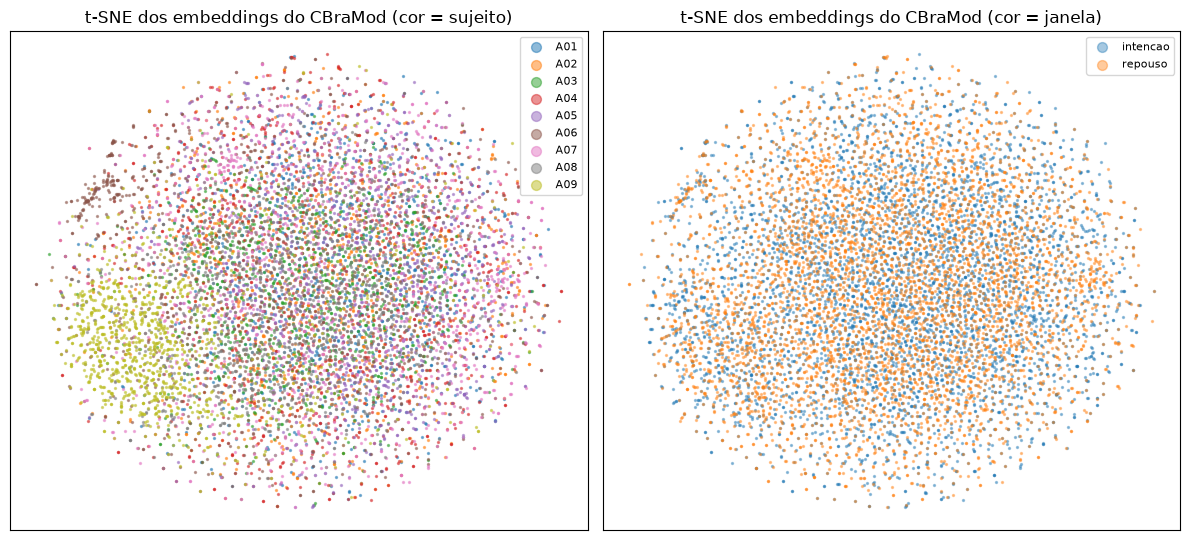

In [12]:
for table in ["fact_embedding", "fact_neighbor"]:
    con.sql(f"CREATE VIEW {table} AS SELECT * FROM '{(data_dir / 'embeddings').as_posix()}/{table}.parquet'")
emb = con.sql("SELECT * FROM fact_embedding").df()
neighbor = con.sql("SELECT * FROM fact_neighbor").df()
print(emb["model_version"].unique(), len(emb), "amostras,", len(neighbor), "pares de vizinhos")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for subject, g in emb.groupby("subject_id"):
    axes[0].scatter(g["tsne_x"], g["tsne_y"], s=2, alpha=0.5, label=subject)
for window, g in emb.groupby("window"):
    axes[1].scatter(g["tsne_x"], g["tsne_y"], s=2, alpha=0.4, label=window)
for ax, title in zip(axes, ["cor = sujeito", "cor = janela"]):
    ax.set_title(f"t-SNE dos embeddings do CBraMod ({title})")
    ax.set_xticks([]), ax.set_yticks([])
    ax.legend(markerscale=5, fontsize=8)
plt.tight_layout()

## Vetores em Parquet e busca no DuckDB

Busca exata, sem servidor: o mesmo Parquet e o mesmo DuckDB da camada analítica. A consulta compara
uma amostra com todas as outras por `array_cosine_similarity` e deve devolver os mesmos vizinhos que
`fact_neighbor` (calculados com o scikit-learn). Com ~10 mil vetores, a busca exata leva segundos;
índice aproximado (HNSW, FAISS) e banco vetorial dedicado só compensariam com milhões de vetores.
O arquivo de vetores é local: sem ele (repositório recém-clonado), rode `python -m src.embed`.

In [13]:
vectors_path = data_dir / "embeddings" / "embedding_vectors.parquet"
query_id = "A08_0train_run_1_t04_repouso"
if vectors_path.exists():
    duck = con.sql(f"""
        SELECT n.sample_id, n.subject_id,
               array_cosine_similarity(q.embedding::FLOAT[4400], n.embedding::FLOAT[4400]) AS sim
        FROM '{vectors_path.as_posix()}' AS q, '{vectors_path.as_posix()}' AS n
        WHERE q.sample_id = '{query_id}' AND n.sample_id <> q.sample_id
        ORDER BY sim DESC
        LIMIT 4
    """).df()
    sk = neighbor[(neighbor["sample_id"] == query_id) & (neighbor["pool"] == "todos") & (neighbor["rank"] <= 4)]
    assert list(duck["sample_id"]) == list(sk["neighbor_sample_id"])
    display(duck.round(4))
else:
    print("embedding_vectors.parquet não encontrado: rode python -m src.embed")

,sample_id,subject_id,sim
0,A02_1test_run_1_t28_intencao,A02,0.5487
1,A03_1test_run_4_t45_intencao,A03,0.4184
2,A03_0train_run_3_t19_intencao,A03,0.3533
3,A02_1test_run_2_t03_repouso,A02,0.3401


## Vizinhos do mesmo paciente

Busca `todos`: dos 10 vizinhos de cada amostra, quantos são do mesmo sujeito? Se o embedding não
soubesse quem é a pessoa, seriam ~11% (1.151 das outras 10.367 amostras são do mesmo sujeito). Mede
também quantas vezes o 1º vizinho é a outra janela do mesmo trial e quantos vizinhos têm a mesma janela.

In [14]:
pool_all = neighbor[neighbor["pool"] == "todos"]
n_total = len(emb)
by_subject = pool_all.groupby("subject_id").agg(mesmo_sujeito=("same_subject", "mean"))
by_subject["acaso"] = (emb["subject_id"].value_counts() - 1) / (n_total - 1)
by_subject.loc["todos"] = [pool_all["same_subject"].mean(), (n_total / 9 - 1) / (n_total - 1)]
display((100 * by_subject).round(1))
print(f"1º vizinho = outra janela do mesmo trial: {100 * pool_all.loc[pool_all['rank'] == 1, 'same_trial'].mean():.2f}%")
print(f"vizinhos com a mesma janela (repouso/intenção): {100 * (pool_all['window'] == pool_all['neighbor_window']).mean():.1f}%")

,mesmo_sujeito,acaso
subject_id,,
A01,14.5,11.1
A02,27.4,11.1
A03,34.8,11.1
A04,13.5,11.1
A05,26.0,11.1
A06,19.2,11.1
A07,12.7,11.1
A08,32.1,11.1
A09,48.1,11.1


1º vizinho = outra janela do mesmo trial: 0.04%
vizinhos com a mesma janela (repouso/intenção): 52.3%


## Auditoria de quase duplicatas entre treino e teste

Os 4 passos da aula:

1. **Vizinho:** para cada amostra de teste, o vizinho mais próximo no treino (busca `treino`, 1º vizinho).
2. **Ordenar:** pares com maior semelhança primeiro; acima de 0,99 seriam quase duplicatas.
3. **Inspecionar:** abrir os pares e conferir os IDs (figura dos pares mais abaixo, que inclui o par de
   maior semelhança).
4. **Corrigir:** o mesmo caso deve ficar no mesmo grupo da divisão; registrar a decisão.

O hash do sinal encontra cópias exatas; o embedding encontra cópias alteradas (filtradas, recortadas).

,sample_id,subject_id,neighbor_sample_id,neighbor_subject_id,cosine_sim
115720,A08_0train_run_1_t04_repouso,A08,A02_1test_run_1_t28_intencao,A02,0.5487
143610,A08_1test_run_5_t09_intencao,A08,A02_1test_run_4_t10_repouso,A02,0.4658
141650,A08_1test_run_1_t05_intencao,A08,A02_1test_run_3_t27_intencao,A02,0.4619
142830,A08_1test_run_3_t27_intencao,A08,A03_0train_run_3_t19_intencao,A03,0.4544
143810,A08_1test_run_5_t29_intencao,A08,A03_0train_run_1_t33_intencao,A03,0.4532


pares teste × treino com cosseno > 0,99: 0
cópias exatas do sinal (hash repetido) em toda a base: 0
         count   mean    std    min    25%    50%    75%    max
pool                                                           
todos   2304.0  0.299  0.052  0.179  0.261  0.294  0.331  0.549
treino  2304.0  0.268  0.055  0.159  0.226  0.259  0.304  0.549


1º vizinho em todas é do mesmo sujeito: 46.6%


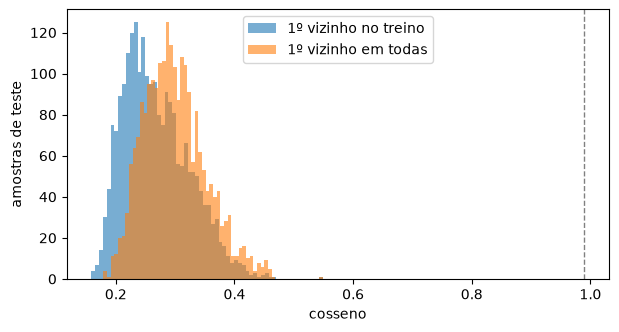

In [15]:
top1 = neighbor[(neighbor["rank"] == 1) & (neighbor["split"] == "teste")]
pairs = top1[top1["pool"] == "treino"].sort_values("cosine_sim", ascending=False)
display(pairs[["sample_id", "subject_id", "neighbor_sample_id", "neighbor_subject_id", "cosine_sim"]]
        .head(5).round(4))
print("pares teste × treino com cosseno > 0,99:", int((pairs["cosine_sim"] > 0.99).sum()))
print("cópias exatas do sinal (hash repetido) em toda a base:", int(emb["signal_sha1"].duplicated().sum()))

fig, ax = plt.subplots(figsize=(7, 3.5))
for pool, label in [("treino", "1º vizinho no treino"), ("todos", "1º vizinho em todas")]:
    ax.hist(top1.loc[top1["pool"] == pool, "cosine_sim"], bins=60, alpha=0.6, label=label)
ax.axvline(0.99, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("cosseno"), ax.set_ylabel("amostras de teste"), ax.legend()
print(top1.groupby("pool")["cosine_sim"].describe().round(3))
print("1º vizinho em todas é do mesmo sujeito:",
      f"{100 * top1.loc[top1['pool'] == 'todos', 'same_subject'].mean():.1f}%")

**Decisão registrada (passo 4):** nenhum par passa de 0,99 (o maior é 0,55) e nenhum sinal se repete
por hash. O par de maior semelhança (A08 × A02, na figura dos pares) é de pessoas diferentes, em
janelas diferentes (repouso × intenção), e os espectros não coincidem: é parecido, não duplicado.
Nada a corrigir. A divisão já é por sujeito, então nenhum caso fica dos dois lados.

## kNN: intenção × repouso a partir dos vizinhos no treino

Sem treinar nada: o escore de cada amostra é a fração dos seus 10 vizinhos no treino (A01–A05) que
são janelas de intenção. Mesma divisão por paciente dos modelos acima, então a área sob a curva ROC
no teste é comparável. Acurácia balanceada no escore 0,5, com intervalo de Wilson.

In [16]:
pool_train = neighbor[neighbor["pool"] == "treino"]
knn = (pool_train.assign(vote=pool_train["neighbor_window"] == "intencao")
       .groupby(["sample_id", "subject_id", "split", "window"], as_index=False)["vote"].mean())
knn["y_true"] = (knn["window"] == "intencao").astype(int)
rows = []
for split, g in knn.groupby("split"):
    y_pred = (g["vote"] > 0.5).astype(int)
    sens = wilson(((y_pred == 1) & (g["y_true"] == 1)).sum(), (g["y_true"] == 1).sum())
    spec = wilson(((y_pred == 0) & (g["y_true"] == 0)).sum(), (g["y_true"] == 0).sum())
    rows.append({"modelo": "kNN CBraMod", "conjunto": split, "AUC": roc_auc_score(g["y_true"], g["vote"]),
                 "sensibilidade": sens[0], "especificidade": spec[0]})
for model in MODELS:
    for split, g in pred[pred["model"] == model].groupby("split"):
        rows.append({"modelo": model, "conjunto": split, "AUC": roc_auc_score(g["y_true"], g["p_intencao"])})
display(pd.DataFrame(rows).round(3))
display(knn[knn["split"] == "teste"].groupby("subject_id")[["vote", "y_true"]]
        .apply(lambda g: roc_auc_score(g["y_true"], g["vote"])).rename("AUC kNN por sujeito").round(3))

,modelo,conjunto,AUC,sensibilidade,especificidade
0,kNN CBraMod,teste,0.535,0.445,0.616
1,kNN CBraMod,validacao,0.554,0.389,0.660
2,eegconformer,teste,0.600,NaN,NaN
3,eegconformer,validacao,0.761,NaN,NaN
4,mlp,teste,0.561,NaN,NaN
5,mlp,validacao,0.599,NaN,NaN


subject_id
A08    0.54
A09    0.53
Name: AUC kNN por sujeito, dtype: float64

## Pares de vizinhos lado a lado

Espectro (Welch) de C3, Cz e C4 de três amostras de teste e do seu 1º vizinho no treino: a de maior,
a de semelhança mediana e a de menor. Gerada por `src/embed.py`, porque precisa do sinal.

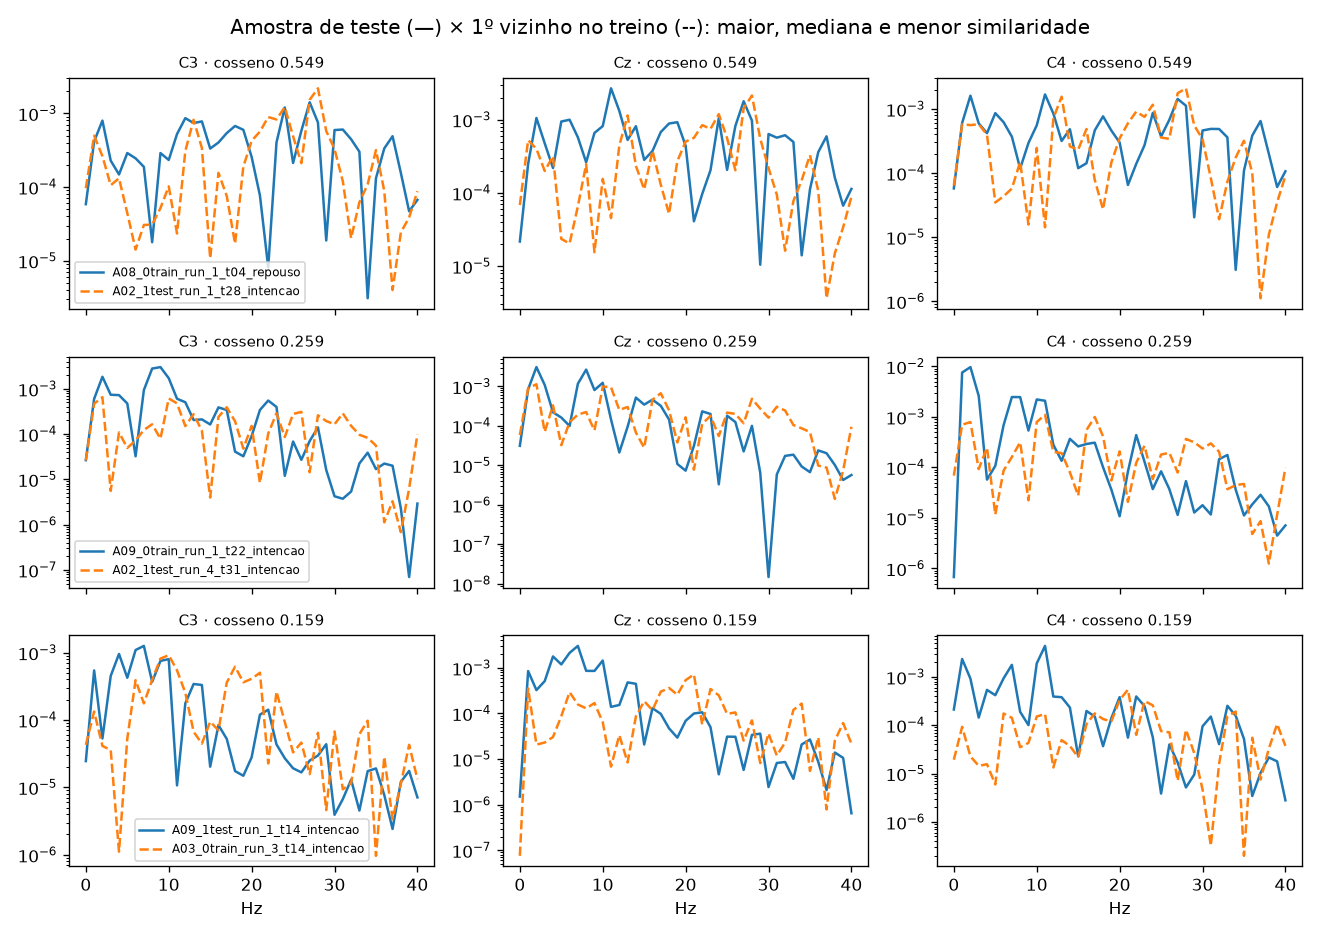

In [17]:
from IPython.display import Image
Image(filename=str(data_dir / "embeddings" / "pares_vizinhos.png"))

## Interpretação

**O que a abordagem acertou:**

- **O sujeito aparece nos vizinhos sem ninguém ter ensinado.** 25,4% dos vizinhos são do mesmo
  sujeito, contra 11,1% do acaso. Varia muito por pessoa: A09 tem 48,1%, A03 34,8% e A08 32,1%,
  enquanto A07 (12,7%) e A04 (13,5%) ficam perto do acaso. No t-SNE, A09 forma um grupo próprio.
  É a medida do **EEG fingerprinting** citado nos riscos de privacidade: um modelo que nunca viu essas
  pessoas já separa parte delas.
- **Explica o domain shift.** O 1º vizinho de uma amostra de teste é do mesmo sujeito em 46,6% das
  vezes, mesmo havendo 8 vezes mais amostras de outros sujeitos. A semelhança "de pessoa" pesa mais
  que a de tarefa, o que ajuda a entender por que a área sob a curva ROC cai entre validação e teste.
- **Sem quase duplicatas.** Nenhum par passa de 0,99 de cosseno (o maior é 0,55), nenhum sinal se
  repete por hash, e a outra janela do mesmo trial quase nunca é o 1º vizinho (0,04%). Não há
  vazamento entre treino e teste por cópia de trechos.

**Onde errou:**

- **Não separa intenção de repouso.** Os vizinhos têm a mesma janela em 52,3% das vezes (o acaso
  é 50%), e no t-SNE as duas janelas se misturam. O kNN fica com área sob a curva ROC de 0,535 no
  teste (0,54 em A08, 0,53 em A09), abaixo do MLP (0,561) e do EEGConformer (0,600). Nos pares lado a
  lado, o vizinho mais parecido de uma amostra de repouso é uma de intenção.

**Por quê:**

- O CBraMod aprendeu a reconstruir EEG clínico, sem rótulo de tarefa. O que domina o embedding é o
  que mais varia nesse tipo de dado: a pessoa, a amplitude e o espectro de fundo. A diferença entre
  imagética e fixação é pequena (dessincronização mu/beta em C3/C4) e não é o que o pré-treino
  favorece.
- O modelo foi usado congelado. Os resultados do artigo vêm de ajuste fino com rótulos.
- A janela de 1 s é mais curta que a de 1,5 s dos outros modelos.

**O que não é possível afirmar:**

- Que o CBraMod não serve para a tarefa: com ajuste fino o resultado pode ser outro, e isso não foi
  testado.
- Que a separação por sujeito vem do cérebro e não do registro (impedância dos eletrodos, ruído,
  sessão): o embedding não distingue as duas coisas.
- Distâncias no t-SNE: ele preserva vizinhanças locais, não distâncias globais; os números vêm do
  espaço de 4.400 dimensões.

**Limitações:** só 2 sujeitos de teste; k = 10 fixado sem ajuste; a escala de entrada (µV/100) e o
filtro (0,3–75 Hz) seguem o pré-treino, mas o 2a tem outra montagem e outro amplificador; o kNN não
é calibrado.